In [1]:
# -----------------------------------------------------------------------
# Libraries and Reproducibility setup
# -----------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm,shapiro
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# -----------------------------------------------------------------------
# DATA
# -----------------------------------------------------------------------
X = np.load('..\Function_7_Data\Week_8_Data/F7_Week_8_inputs.npy')
y = np.load('..\Function_7_Data\Week_8_Data/F7_Week_8_outputs.npy')

n, d = X.shape
print(f"n = {n} observations, d = {d} dimensions")
print(f"y range: [{y.min():.4f}, {y.max():.4f}]  (ratio max/min = {y.max()/y.min():.1f})")

n = 37 observations, d = 6 dimensions
y range: [0.0027, 2.4050]  (ratio max/min = 890.2)


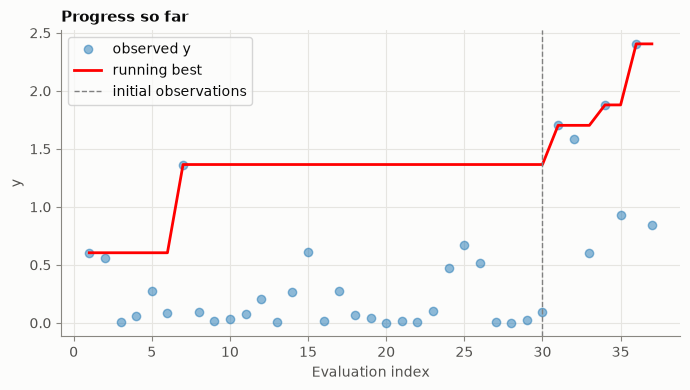

In [3]:
#--------------------------------------------------------------------------
# Optimisation history: Progress so far
#--------------------------------------------------------------------------
plt.figure(figsize=(7, 4))
running_best = np.maximum.accumulate(y)
plt.plot(range(1, n + 1), y, "o", alpha=0.5, label="observed y")
plt.plot(range(1, n + 1), running_best, "r-", lw=2, label="running best")
plt.axvline(30, color="gray", ls="--", lw=1, label="initial observations")
plt.xlabel("Evaluation index")
plt.ylabel("y")
plt.title("Progress so far")
plt.legend()
plt.tight_layout()


Inputs: already confined to the unit hypercube [0,1]^6 -> no rescaling needed.

Outputs: y is strictly positive, spans almost 3 orders of magnitude (0.0027 -> 2.40), 
and is heavily right-skewed (a handful of large values, a mass of values close to 0). 

A log-transform g = log(y) is well suited for a strictly-positive, right-skewed target.


Shapiro-Wilk normality test (p-value; higher = more Gaussian-like):
  raw y      : W=0.744, p=0.0000
  log(y)     : W=0.945, p=0.0688



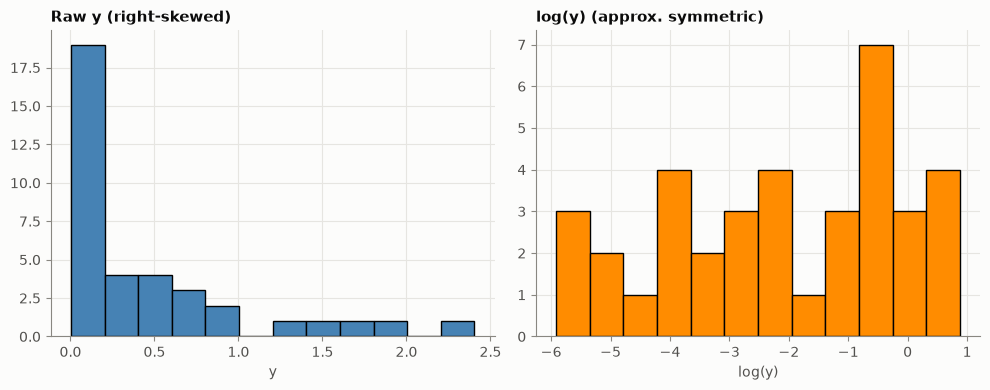

In [4]:
# -----------------------------------------------------------------------
# DATA TRANSFORMATION
# -----------------------------------------------------------------------
print("""\nInputs: already confined to the unit hypercube [0,1]^6 -> no rescaling needed.

Outputs: y is strictly positive, spans almost 3 orders of magnitude (0.0027 -> 2.40), 
and is heavily right-skewed (a handful of large values, a mass of values close to 0). 

A log-transform g = log(y) is well suited for a strictly-positive, right-skewed target.
""")

y_log = np.log(y)

sw_raw = shapiro(y)
sw_log = shapiro(y_log)
print(f"\nShapiro-Wilk normality test (p-value; higher = more Gaussian-like):")
print(f"  raw y      : W={sw_raw.statistic:.3f}, p={sw_raw.pvalue:.4f}")
print(f"  log(y)     : W={sw_log.statistic:.3f}, p={sw_log.pvalue:.4f}\n")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y, bins=12, color="steelblue", edgecolor="k")
axes[0].set_title("Raw y (right-skewed)")
axes[0].set_xlabel("y")
axes[1].hist(y_log, bins=12, color="darkorange", edgecolor="k")
axes[1].set_title("log(y) (approx. symmetric)")
axes[1].set_xlabel("log(y)")
plt.tight_layout()


Fitted kernel:
  1.12**2 * Matern(length_scale=[1.59, 1.1, 0.871, 0.553, 0.481, 0.74], nu=2.5) + WhiteKernel(noise_level=1e-06)

Learned ARD length-scales per dimension (smaller = more influential):
  x0: 1.5864
  x1: 1.1015
  x2: 0.8710
  x3: 0.5527
  x4: 0.4811
  x5: 0.7401

Signal variance (amplitude^2): 1.2504
Noise variance: 0.0000



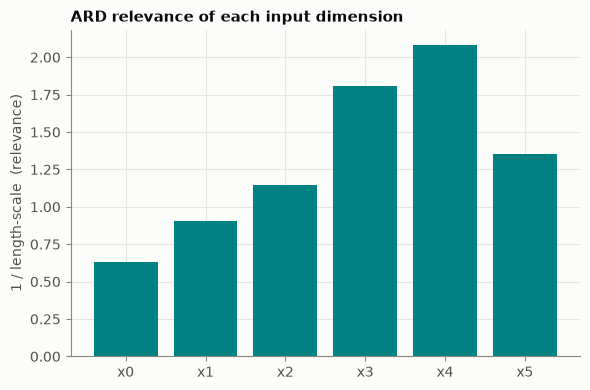

In [5]:
# -----------------------------------------------------------------------
# SURROGATE MODEL: Gaussian Process with Matern-5/2 ARD kernel
# -----------------------------------------------------------------------

kernel = (
    ConstantKernel(1.0, (1e-2, 1e3))
    * Matern(length_scale=np.ones(d), length_scale_bounds=(1e-2, 1e2), nu=2.5)
    + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-6, 1.0))
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    normalize_y=True,  
    n_restarts_optimizer=25,
    random_state=SEED,
)
gp.fit(X, y_log)

print("\nFitted kernel:")
print(" ", gp.kernel_)

k1 = gp.kernel_.k1  # Constant * Matern
ard_lengthscales = k1.k2.length_scale
signal_var = k1.k1.constant_value
noise_var = gp.kernel_.k2.noise_level
print("\nLearned ARD length-scales per dimension (smaller = more influential):")
for i, ls in enumerate(ard_lengthscales):
    print(f"  x{i}: {ls:.4f}")
print(f"\nSignal variance (amplitude^2): {signal_var:.4f}")
print(f"Noise variance: {noise_var:.4f}\n")

# Bar chart of inverse length-scale = "relevance" per dimension
plt.figure(figsize=(6, 4))
importance = 1.0 / ard_lengthscales
plt.bar([f"x{i}" for i in range(d)], importance, color="teal")
plt.ylabel("1 / length-scale  (relevance)")
plt.title("ARD relevance of each input dimension")
plt.tight_layout()


Leave-one-out RMSE (log-space): 1.3733



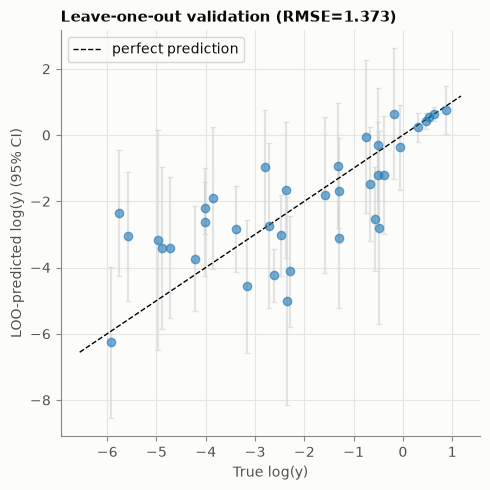

In [6]:
# -----------------------------------------------------------------------
# Leave-one-out cross-validation
# -----------------------------------------------------------------------
loo = LeaveOneOut()
preds, stds, trues = [], [], []
for train_idx, test_idx in loo.split(X):
    gp_cv = GaussianProcessRegressor(
        kernel=kernel, normalize_y=True, n_restarts_optimizer=5, random_state=SEED
    )
    gp_cv.fit(X[train_idx], y_log[train_idx])
    mu, sigma = gp_cv.predict(X[test_idx], return_std=True)
    preds.append(mu[0])
    stds.append(sigma[0])
    trues.append(y_log[test_idx][0])
preds, stds, trues = np.array(preds), np.array(stds), np.array(trues)
rmse = np.sqrt(np.mean((preds - trues) ** 2))
print(f"\nLeave-one-out RMSE (log-space): {rmse:.4f}\n")

plt.figure(figsize=(5, 5))
plt.errorbar(trues, preds, yerr=1.96 * stds, fmt="o", alpha=0.6, ecolor="lightgray", capsize=2)
lims = [min(trues.min(), preds.min()) - 0.3, max(trues.max(), preds.max()) + 0.3]
plt.plot(lims, lims, "k--", lw=1, label="perfect prediction")
plt.xlabel("True log(y)")
plt.ylabel("LOO-predicted log(y) (95% CI)")
plt.title(f"Leave-one-out validation (RMSE={rmse:.3f})")
plt.legend()
plt.tight_layout()

In [7]:
# -----------------------------------------------------------------------
# ACQUISITION FUNCTION: Expected Improvement (EI)
# -----------------------------------------------------------------------

def expected_improvement(Xq, gp, g_best, xi=0.01):
    Xq = np.atleast_2d(Xq)
    mu, sigma = gp.predict(Xq, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    imp = mu - g_best - xi
    Z = imp / sigma
    ei = imp * norm.cdf(Z) + sigma * norm.pdf(Z)
    ei = np.where(sigma < 1e-9, 0.0, ei)
    return ei

g_best = y_log.max()
print(f"\nCurrent best (log-space): {g_best:.4f}  ->  y_best = {np.exp(g_best):.4f}")
print(f"Achieved at x = {X[np.argmax(y_log)]}")

def neg_ei(x):
    return -expected_improvement(x, gp, g_best, xi=0.01)[0]

bounds = [(0.0, 1.0)] * d
n_restarts_acq = 60
best_x, best_ei = None, -np.inf
for i in range(n_restarts_acq):
    x0 = rng.uniform(0, 1, size=d)
    res = minimize(neg_ei, x0, bounds=bounds, method="L-BFGS-B")
    ei_val = -res.fun
    if ei_val > best_ei:
        best_ei = ei_val
        best_x = res.x

mu_next, sigma_next = gp.predict(best_x.reshape(1, -1), return_std=True)
# Back-transform: predictive mean of y under a log-normal posterior
mean_y_next = np.exp(mu_next[0] + 0.5 * sigma_next[0] ** 2)
median_y_next = np.exp(mu_next[0])

print("\n" + "=" * 60)
print("NEXT QUERY POINT PROPOSED BY EI")
print("=" * 60)
print("x_next =", np.round(best_x, 6))
print(f"Expected Improvement value: {best_ei:.6f}")
print(f"GP posterior in log-space : mean={mu_next[0]:.6f}, std={sigma_next[0]:.6f}")
print(f"Predicted y (log-normal median) : {median_y_next:.6f}")
print(f"Predicted y (log-normal mean)   : {mean_y_next:.6f}")


Current best (log-space): 0.8775  ->  y_best = 2.4050
Achieved at x = [0.       0.275739 0.455065 0.270517 0.388871 0.710439]

NEXT QUERY POINT PROPOSED BY EI
x_next = [0.       0.48683  1.       0.684096 0.       1.      ]
Expected Improvement value: 0.166331
GP posterior in log-space : mean=0.079385, std=1.158901
Predicted y (log-normal median) : 1.082621
Predicted y (log-normal mean)   : 2.118929



1-D slices through the GP posterior (in original y units) around the
proposed next point, one panel per input dimension, all other
dimensions held fixed at x_next. This visualises the fitted surrogate
and the ARD length-scales directly, and shows where EI wants to go.



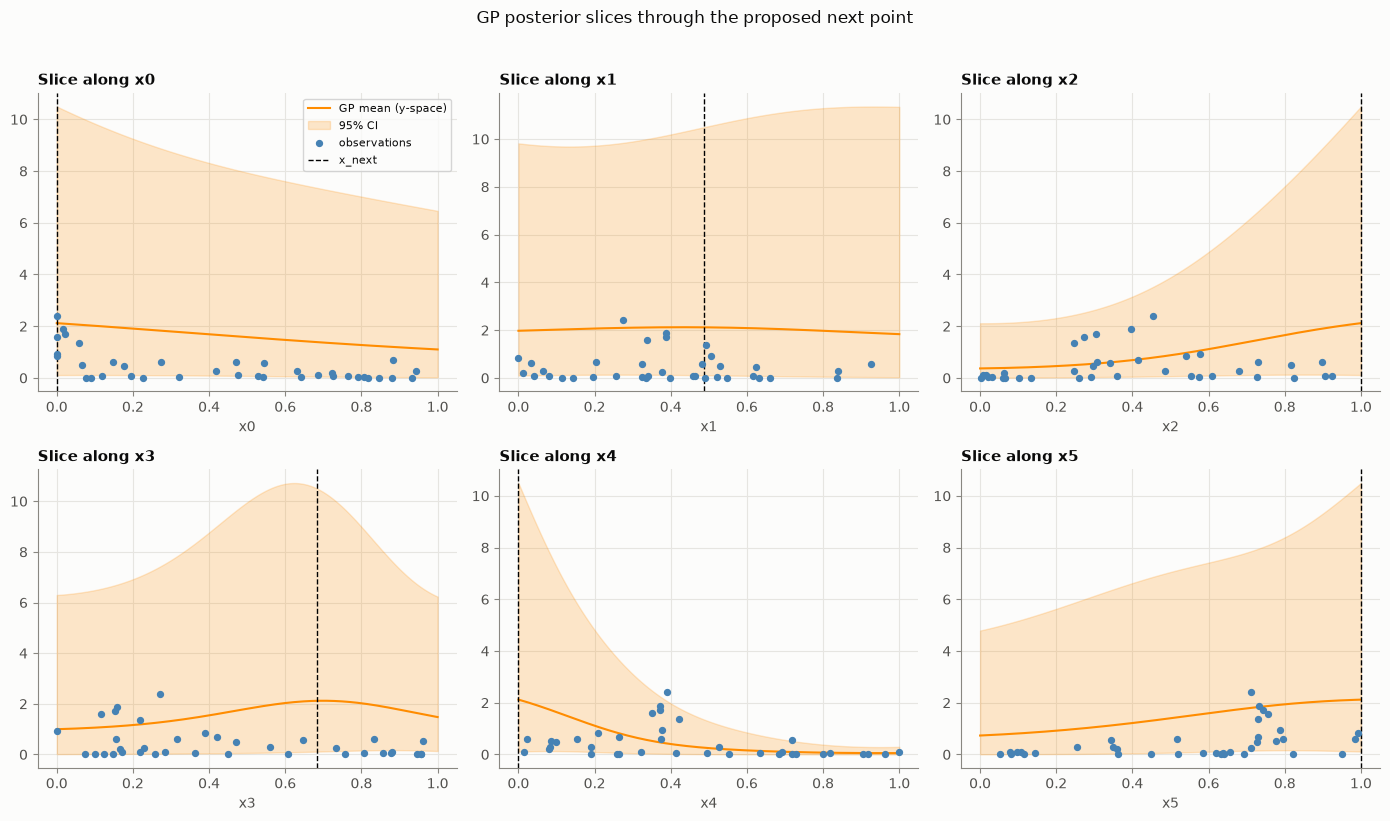

In [8]:
# -----------------------------------------------------------------------
# PLOTS
# -----------------------------------------------------------------------

print("""\n1-D slices through the GP posterior (in original y units) around the
proposed next point, one panel per input dimension, all other
dimensions held fixed at x_next. This visualises the fitted surrogate
and the ARD length-scales directly, and shows where EI wants to go.\n""")

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
grid = np.linspace(0, 1, 200)
for i, ax in enumerate(axes.flat):
    Xs = np.tile(best_x, (200, 1))
    Xs[:, i] = grid
    mu_s, sigma_s = gp.predict(Xs, return_std=True)
    y_mu = np.exp(mu_s + 0.5 * sigma_s ** 2)
    y_lo = np.exp(mu_s - 1.96 * sigma_s)
    y_hi = np.exp(mu_s + 1.96 * sigma_s)
    ax.plot(grid, y_mu, color="darkorange", label="GP mean (y-space)")
    ax.fill_between(grid, y_lo, y_hi, color="darkorange", alpha=0.2, label="95% CI")
    ax.scatter(X[:, i], y, color="steelblue", s=18, zorder=5, label="observations")
    ax.axvline(best_x[i], color="k", ls="--", lw=1, label="x_next")
    ax.set_title(f"Slice along x{i}")
    ax.set_xlabel(f"x{i}")
    if i == 0:
        ax.legend(fontsize=8)
plt.suptitle("GP posterior slices through the proposed next point", y=1.02)
plt.tight_layout()